# Taxi: logistic vs quadratic logistic regression (big classification dataset)

**Data:** UCI *Taxi Service Trajectory* (Porto, ECML PKDD 2015), ~1.7M trips.
**Target:** `CALL_TYPE`: A = booked via the central, B = from a taxi stand, C = hailed on the street.
**Metric:** logistic loss (log-loss).

Step 4 of the lab: we repeat steps 1-3 with **logistic regression** instead of linear
regression: learning curves for the plain and the quadratic model, then cross-validation.

Features (see `lab/data_taxi.py`): hour and weekday of the start, trip duration
(number of GPS points), start/end coordinates and the start-end distance. The columns
`ORIGIN_CALL` / `ORIGIN_STAND` are **not** used because they reveal the label directly.

In [1]:
import sys
sys.path.append("..")  # make the lab/ package (one folder up) importable

import pandas as pd
from IPython.display import display

from lab import FIGURES_DIR, RESULTS_DIR
from lab.experiment import baseline_score, cross_validate_models, run_learning_curve, summarize
from lab.models import make_model
from lab.plotting import plot_learning_curve

from lab.sampler import linear_sizes, log_sizes, sample_training_sets

RESULTS_DIR.mkdir(exist_ok=True)
pd.set_option("display.float_format", "{:.4g}".format)

In [2]:
DATASET = "taxi"
TASK = "classification"
KINDS = ["logistic", "quadratic_logistic"]
N_REPEATS = 5

# RUN_FULL = False: quick run on a random subset (a laptop handles it in seconds).
# RUN_FULL = True: all ~1.7M trips; run it on the JSI servers, e.g.
#   jupyter nbconvert --to notebook --execute --inplace notebooks/taxi.ipynb
RUN_FULL = False
MAX_ROWS = None if RUN_FULL else 20_000
RUN_NAME = f"{DATASET}_{'full' if RUN_FULL else 'small'}"
CV_MAX_ROWS = 100_000   # CV on a random subset of the training part (speed)

## Load the data

In [3]:
from lab.data_taxi import load_taxi, month_groups, split_taxi

# time = start time of every trip; not a feature, only used for splitting
X, y, time = load_taxi(max_rows=MAX_ROWS)
print(X.shape, "trips from", time.min().date(), "to", time.max().date())
display(X.head())
print("class proportions:")
print(y.value_counts(normalize=True))

(20000, 8) trips from 2013-07-01 to 2014-07-01


,hour,weekday,n_points,start_lon,start_lat,end_lon,end_lat,distance_km
0,22,4,44,-8.634,41.17,-8.61,41.15,2.91
1,4,1,30,-8.594,41.17,-8.562,41.15,3.215
2,23,3,104,-8.628,41.16,-8.72,41.27,14.4
3,18,2,39,-8.649,41.17,-8.661,41.16,1.052
4,3,5,30,-8.605,41.16,-8.612,41.15,1.576


class proportions:
CALL_TYPE
B   0.4829
C    0.305
A    0.212
Name: proportion, dtype: float64


## Train / validation split: temporal

The data cover one full year (July 2013 - June 2014). We train on the trips **before** a
cutoff date and validate on the **last ~20% of days** (`split_taxi` in `lab/data_taxi.py`).

Why not a random split?
- It is the realistic use case: a model is trained on past trips and used on new ones.
- Trips on the same day share conditions (weather, events, holidays). A random split puts
  trips of the same day on both sides, so validation would partly test on "days the model
  has already seen".
- The class mix drifts slowly over the year (stand trips B: ~51% in summer 2013, ~47% in
  2014; street hails C: ~28% to ~33%). A temporal split shows whether this hurts.

Inside the training part the learning-curve samples are still drawn at random: the
learning curve is about the *number* of training points.

In [4]:
X_train, X_val, y_train, y_val = split_taxi(X, y, time)
print(f"training part: {len(X_train):,} rows, validation: {len(X_val):,} rows")
display(pd.DataFrame({"train": y_train.value_counts(normalize=True),
                      "validation": y_val.value_counts(normalize=True)}).round(3))

training: trips before 2014-04-23, validation: from 2014-04-23 on
training part: 15,983 rows, validation: 4,017 rows


,train,validation
CALL_TYPE,,
B,0.489,0.458
C,0.299,0.33
A,0.212,0.212


In [5]:
# How many features does each model actually see? (after one-hot / squaring)
# Compare these numbers with the training-set sizes on the x-axis below.
for kind in KINDS:
    prep = make_model(kind).named_steps["prep"].fit(X_train)
    print(f"{kind:>20}: {prep.transform(X_train.iloc[:5]).shape[1]} features")

            logistic: 37 features
  quadratic_logistic: 58 features


With 3 classes, multinomial logistic regression learns one weight per feature *and class*,
so the number of parameters is about 3x the feature count.

## Step 4 (= steps 1 & 2 with logistic regression): learning curves

In [6]:
# Log-spaced sizes from 10 up to the whole training part: 10, 20, 40, ...
sizes = log_sizes(10, len(X_train), 15)
print(sizes)

samples = sample_training_sets(y_train, sizes, N_REPEATS, TASK)
curve = run_learning_curve(X_train, y_train, X_val, y_val, KINDS, samples, TASK)
curve.to_csv(RESULTS_DIR / f"{RUN_NAME}_curve.csv", index=False)

stats = summarize(curve)
display(stats)
print(f"total fitting time: {curve['fit_seconds'].sum():.0f} s")

[10, 17, 29, 49, 82, 139, 236, 400, 677, 1147, 1942, 3290, 5572, 9437, 15983]
size       10


size       17


size       29


size       49


size       82


...

size     5572


size     9437


size    15983


model   size train_score                                \
                                     mean       std    median       q25   
0             logistic     10   0.0001982 4.428e-05 0.0002027 0.0001826   
1             logistic     17    0.000275 0.0001128 0.0002478 0.0001742   
2             logistic     29   0.0002925 0.0001106 0.0002224 0.0002168   
3             logistic     49   0.0002437 8.982e-05 0.0002338 0.0001741   
4             logistic     82      0.3797   0.04913     0.413    0.3333   
5             logistic    139       0.662   0.04758    0.6573    0.6513   
6             logistic    236      0.8027   0.03651    0.8138    0.8101   
7             logistic    400      0.8793    0.0166     0.883    0.8777   
8             logistic    677       0.931  0.009525    0.9283     0.928   
9             logistic   1147      0.9421   0.01167    0.9437     0.932   
10            logistic   1942      0.9635  0.008329    0.9616     0.958   
11            logistic   3290      0.9683  0.002928    0.9688    0.9685   
12            logistic   5572      0.9729  0.003524    0.9733    0.9711   
13            logistic   9437      0.9757  0.002381    0.9759    0.9748   
14            logistic  15983      0.9769         0    0.9769    0.9769   
15  quadratic_logistic     10   0.0001619 7.861e-05 0.0001283 0.0001077   
16  quadratic_logistic     17   0.0001758 8.512e-05 0.0001825 0.0001056   
17  quadratic_logistic     29    0.000189 7.189e-05 0.0001902 0.0001329   
18  quadratic_logistic     49   0.0002581 6.775e-05 0.0002559 0.0002289   
19  quadratic_logistic     82     0.02266    0.0502 0.0002352 0.0002112   
20  quadratic_logistic    139      0.5164  0.009092    0.5185    0.5116   
21  quadratic_logistic    236       0.721   0.04799    0.7013    0.6862   
22  quadratic_logistic    400      0.8201    0.0173    0.8142    0.8112   
23  quadratic_logistic    677      0.8838   0.02394    0.8786    0.8743   
24  quadratic_logistic   1147       0.908    0.0154    0.9156    0.8938   
25  quadratic_logistic   1942       0.932   0.00847     0.935    0.9278   
26  quadratic_logistic   3290      0.9444  0.004396    0.9444    0.9405   
27  quadratic_logistic   5572      0.9534   0.00256    0.9531     0.953   
28  quadratic_logistic   9437      0.9603  0.004478    0.9601    0.9596   
29  quadratic_logistic  15983      0.9609         0    0.9609    0.9609   

             val_score                                 
         q75      mean       std median    q25    q75  
0  0.0002276      5.19     1.286   5.28  4.405  6.309  
1  0.0003554     7.262     1.888  6.692  5.826  8.724  
2  0.0003569      9.16     1.911  8.328  8.014  9.073  
3  0.0002745     17.78     1.433  17.99  16.48  18.09  
4      0.415     6.979     1.331  7.334   6.08  7.487  
5     0.6926     2.723    0.5012  2.706  2.332  3.191  
6     0.8205     1.603    0.0937  1.578  1.558  1.615  
7     0.8908     1.183   0.05942  1.166  1.156  1.213  
8     0.9403      1.04   0.02568  1.036  1.018  1.051  
9     0.9491     1.023   0.01114   1.02  1.016  1.024  
10    0.9697     1.001  0.003238 0.9998 0.9995  1.002  
11    0.9697    0.9904  0.003186 0.9913 0.9888 0.9915  
12    0.9745    0.9862  0.001713 0.9857  0.985 0.9865  
13    0.9778    0.9849 0.0005833 0.9852 0.9844 0.9853  
14    0.9769    0.9827         0 0.9827 0.9827 0.9827  
15 0.0002301     8.677     2.625  8.064  7.589  10.96  
16 0.0001856     11.39     2.995  10.79  9.531  14.05  
17 0.0002058     11.86     1.961   11.7  10.05  13.08  
18 0.0003166     17.55     1.572  17.42  16.69  18.72  
19 0.0002829      19.9     1.402  20.16  19.68  20.47  
20    0.5223     6.712     1.087  6.217  5.884  7.701  
21    0.7356     3.281    0.2458  3.219  3.099  3.521  
22    0.8255     1.814    0.2801  1.813    1.6  2.082  
23     0.905      1.12   0.07046  1.086  1.085  1.147  
24    0.9207     1.097   0.07098  1.063  1.049  1.166  
25    0.9377     1.016   0.01418  1.018  1.008  1.024  
26    0.9473    0.9904  0.006383 0.9883 0.9869 0

total fitting time: 13 s


baseline validation log-loss: 1.0552


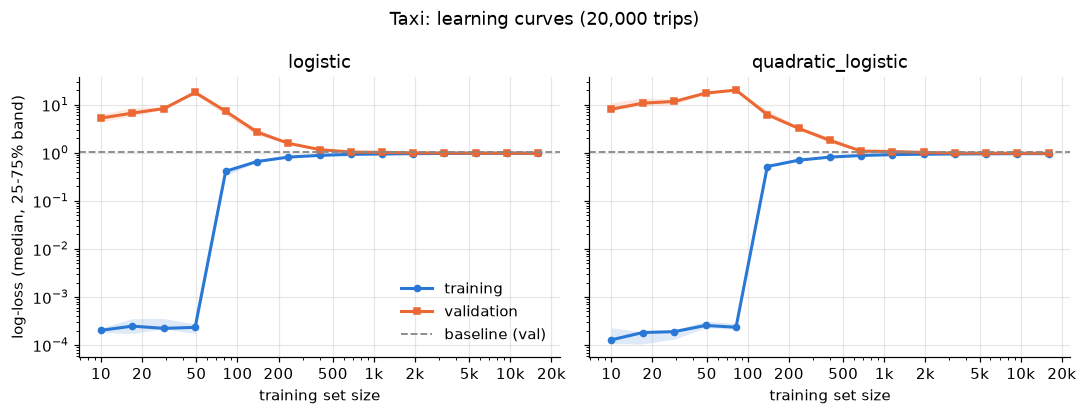

In [7]:
# Reference: always predict the class proportions of the training part.
# Its log-loss is the entropy of the class distribution (~1.04 here).
baseline = baseline_score(X_train, y_train, X_val, y_val, TASK)
print(f"baseline validation log-loss: {baseline:.4f}")

fig = plot_learning_curve(curve, "log-loss", f"Taxi: learning curves ({len(X):,} trips)",
                          baseline=baseline, log_x=True, log_y=True,
                          path=FIGURES_DIR / f"{RUN_NAME}_learning_curves.png")

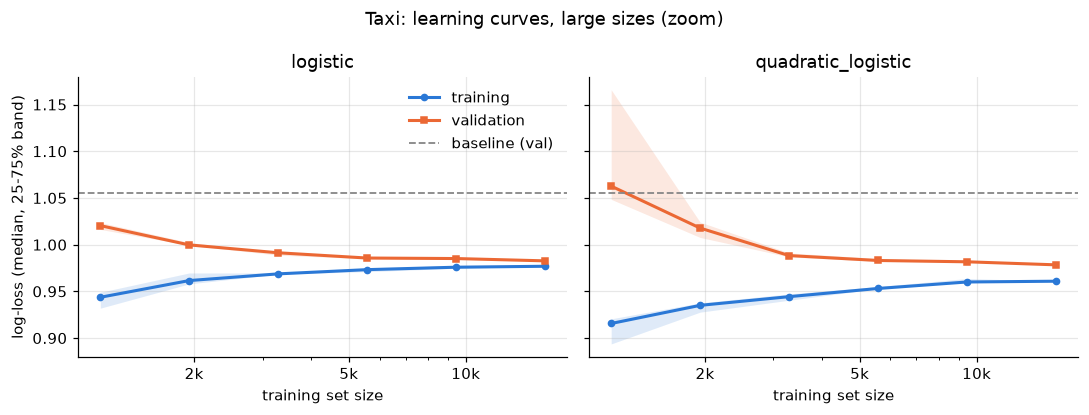

In [8]:
# Zoom in on the large training sets, where the differences are small.
large = curve[curve["size"] >= 1000]
fig = plot_learning_curve(large, "log-loss", "Taxi: learning curves, large sizes (zoom)",
                          baseline=baseline, log_x=True,
                          path=FIGURES_DIR / f"{RUN_NAME}_learning_curves_zoom.png")

### What the curves show

**Small samples.** With few trips (compared to the number of parameters) the three classes
can be separated perfectly in feature space. Without regularization, logistic regression
then pushes its weights towards infinity and predicts probabilities of almost exactly 0
and 1, so the **training log-loss is ~0**. On new trips those over-confident predictions
are often wrong, and log-loss punishes a confident mistake very hard (`-log(p)` with
`p ≈ 0`). That is why the **validation log-loss is far above the baseline**. As with
linear regression it is worst just before the data stop being perfectly separable, which
happens once the number of samples is of the order of the number of parameters (~3x the
feature count printed above); after that point the training loss jumps up and the
validation loss drops quickly.

**Large samples.** The two curves meet at a log-loss only a little below the baseline.
The gap (variance) disappears, but the level stays high: from the time and place of a
trip we can only partly guess how the taxi was called. This is **bias** (the features and
a linear decision rule cannot explain more), not lack of data, so adding even more trips
would barely help.

**Plain vs quadratic.** The quadratic model needs more data before it stops overfitting
(more parameters), but with enough trips it ends slightly lower: being able to model
curved boundaries (e.g. "trips starting near the centre") lowers the bias a bit.

## Step 3 for classification: cross-validation
5-fold CV on (a random subset of) the training part only. To be consistent with the
temporal split, the folds hold out **whole months** (`GroupKFold` with the month as group)
instead of randomly shuffled trips.

In [9]:
from sklearn.model_selection import GroupKFold

cv = cross_validate_models(X_train, y_train, KINDS, TASK, folds=GroupKFold(n_splits=5),
                           groups=month_groups(time.loc[X_train.index]), max_rows=CV_MAX_ROWS)
cv.to_csv(RESULTS_DIR / f"{RUN_NAME}_cv.csv", index=False)

largest = stats[stats["size"] == stats["size"].max()]
curve_end = pd.DataFrame({
    "model": largest["model"],
    "curve_train": largest[("train_score", "median")],
    "curve_val": largest[("val_score", "median")],
})
comparison = cv.merge(curve_end, on="model")
display(comparison)
print("CV chooses:", cv.loc[cv["cv_mean"].idxmin(), "model"])

,model,cv_mean,cv_std,n_rows,curve_train,curve_val
0,logistic,0.9828,0.01073,15983,0.9769,0.9827
1,quadratic_logistic,0.9717,0.01017,15983,0.9609,0.9784


CV chooses: quadratic_logistic


### CV vs. the learning curves

With this many trips all three estimates (training error, validation error, CV error)
are close to each other: the models are too simple to overfit thousands of samples, so
the training error is barely optimistic. CV and the validation curve should agree on the
better model (the quadratic one, by a small margin). The validation set lies in the
*future* (the last months), while the CV folds are months from within the training period;
because the class mix drifts over the year, the validation error can be slightly higher
than the CV error. Compare this with the small
automobile dataset, where training, validation and CV errors differed by orders of
magnitude.